# Heart Attack Risk Prediction – Logistic Regression vs Decision Tree

**Goal:** Predict whether a patient has a *higher chance* (`Target = 1`) or *lower chance* (`Target = 0`) of a heart attack using classical machine learning (no deep learning).

**Notebook sections**
1. Import Libraries / Dataset
2. Data Visualization and Exploration
3. Data Pre-processing and Cleaning (incl. feature engineering and feature importance)
4. Model Building (train/test split, Logistic Regression, Decision Tree, hyperparameter tuning)
5. Performance Evaluation and Conclusion

## 1. Import Libraries / Dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# Load the dataset (change the path if your CSV is in another folder)
df = pd.read_csv("Heart_Attack_Analysis_Data.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


## 2. Data Visualization and Exploration

### 2.1 Sanity check – first rows and features

In [3]:
display(df.head(10))
print("\nColumns:", list(df.columns))

,Age,Sex,CP_Type,BloodPressure,Cholestrol,BloodSugar,ECG,MaxHeartRate,ExerciseAngia,FamilyHistory,Target
0,63,1,3,145,233,1,0,150,0,2,1
1,37,1,2,130,250,0,1,187,0,1,1
2,41,0,1,130,204,0,0,172,0,0,1
3,56,1,1,120,236,0,1,178,0,1,1
4,57,0,0,120,354,0,1,163,1,0,1
5,57,1,0,140,192,0,1,148,0,0,1
6,56,0,1,140,294,0,0,153,0,0,1
7,44,1,1,120,263,0,1,173,0,0,1
8,52,1,2,172,199,1,1,162,0,0,1
9,57,1,2,150,168,0,1,174,0,1,1



Columns: ['Age', 'Sex', 'CP_Type', 'BloodPressure', 'Cholestrol', 'BloodSugar', 'ECG', 'MaxHeartRate', 'ExerciseAngia', 'FamilyHistory', 'Target']


**Sanity check:** The dataset has 10 input features (Age, Sex, CP_Type, BloodPressure, Cholestrol, BloodSugar, ECG, MaxHeartRate, ExerciseAngia, FamilyHistory) and one target column `Target` (0 = less chance, 1 = more chance). All columns match the problem statement.

*Note:* The problem statement describes chest pain type as values 1-4, but in the CSV `CP_Type` is coded 0-3. It is just a shifted label (0 = typical angina ... 3 = asymptomatic), so it does not affect the analysis.

### 2.2 Shape, description and data types

In [4]:
print("Shape of dataset (rows, columns):", df.shape)
print()
df.info()

Shape of dataset (rows, columns): (303, 11)

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            303 non-null    int64
 1   Sex            303 non-null    int64
 2   CP_Type        303 non-null    int64
 3   BloodPressure  303 non-null    int64
 4   Cholestrol     303 non-null    int64
 5   BloodSugar     303 non-null    int64
 6   ECG            303 non-null    int64
 7   MaxHeartRate   303 non-null    int64
 8   ExerciseAngia  303 non-null    int64
 9   FamilyHistory  303 non-null    int64
 10  Target         303 non-null    int64
dtypes: int64(11)
memory usage: 26.2 KB


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
Sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
CP_Type,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
BloodPressure,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
Cholestrol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
BloodSugar,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
ECG,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
MaxHeartRate,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
ExerciseAngia,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
FamilyHistory,303.0,1.204620,1.096825,0.0,0.0,1.0,2.0,5.0


In [6]:
print("Target distribution:")
print(df["Target"].value_counts())
print()
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Target distribution:
Target
1    165
0    138
Name: count, dtype: int64

Target
1    54.46
0    45.54
Name: proportion, dtype: float64


### 2.3 Visualizations

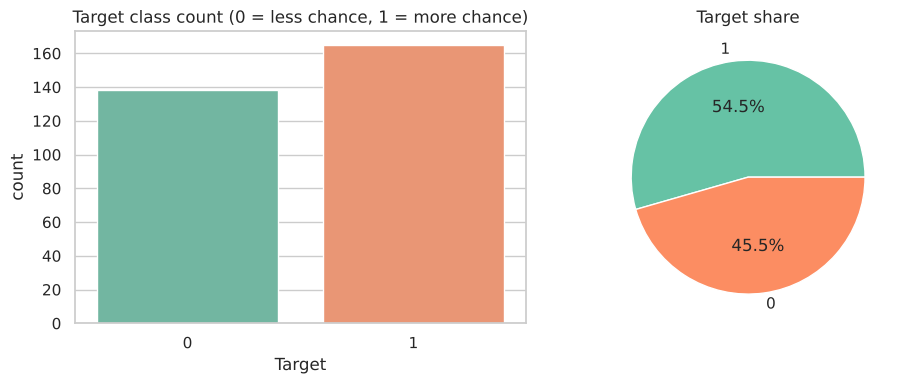

In [7]:
# Target balance
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Target", data=df, ax=ax[0], palette="Set2")
ax[0].set_title("Target class count (0 = less chance, 1 = more chance)")
df["Target"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], colors=sns.color_palette("Set2"))
ax[1].set_ylabel("")
ax[1].set_title("Target share")
plt.tight_layout(); plt.show()

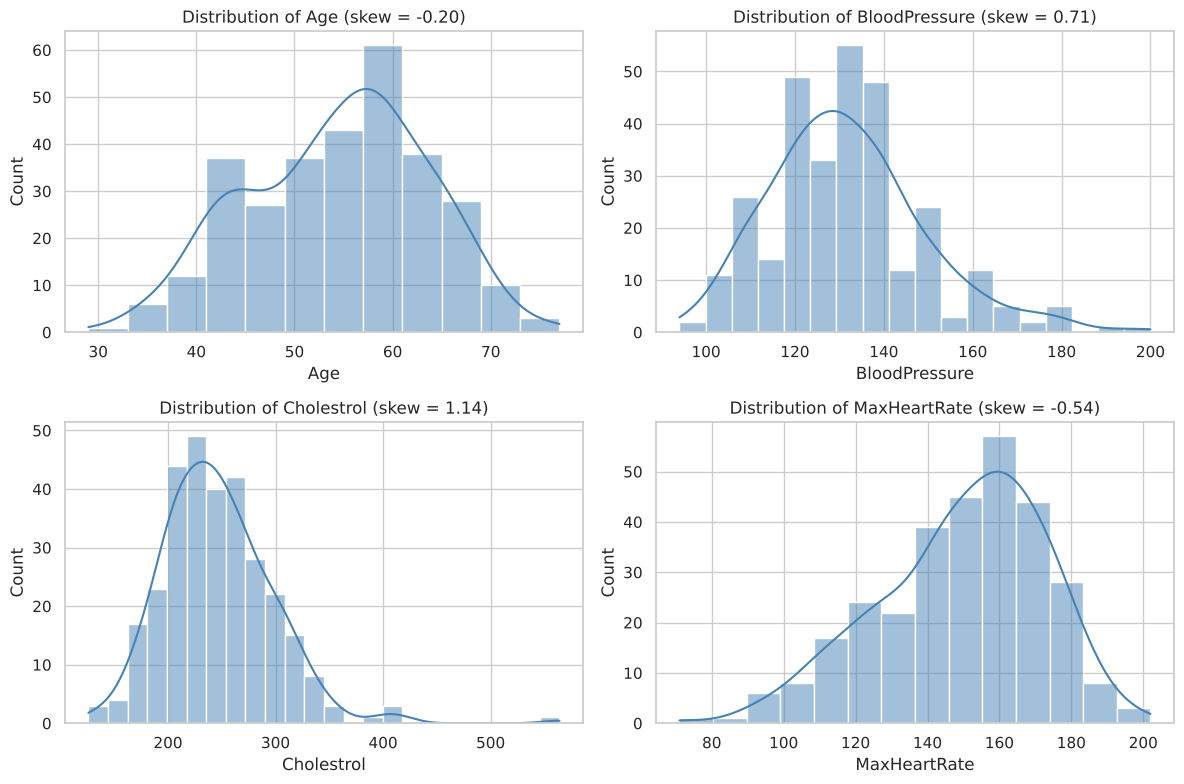

In [8]:
# Distribution of numerical features
num_cols = ["Age", "BloodPressure", "Cholestrol", "MaxHeartRate"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col} (skew = {df[col].skew():.2f})")
plt.tight_layout(); plt.show()

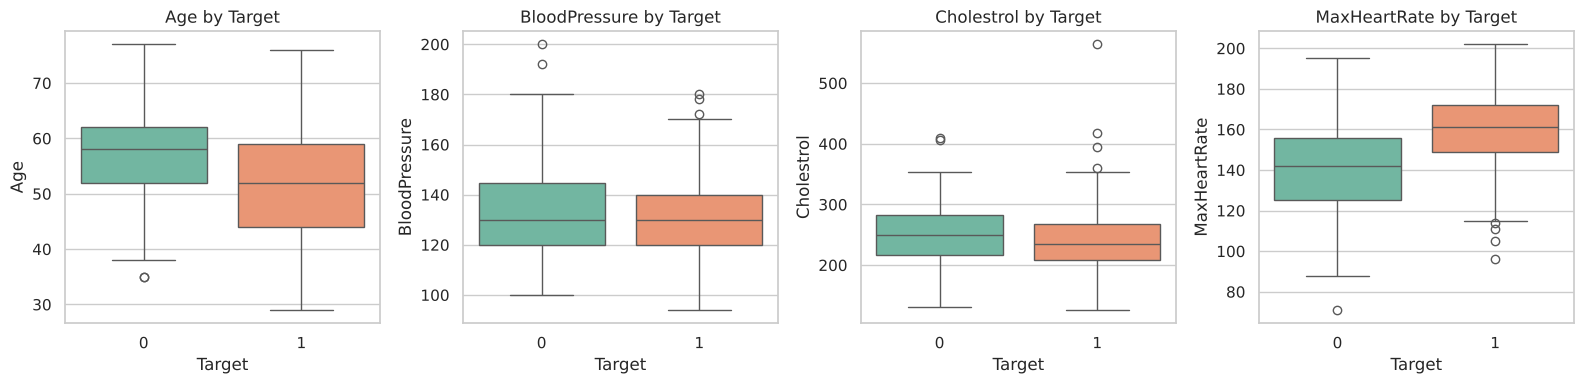

In [9]:
# Numerical features vs Target
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="Target", y=col, data=df, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Target")
plt.tight_layout(); plt.show()

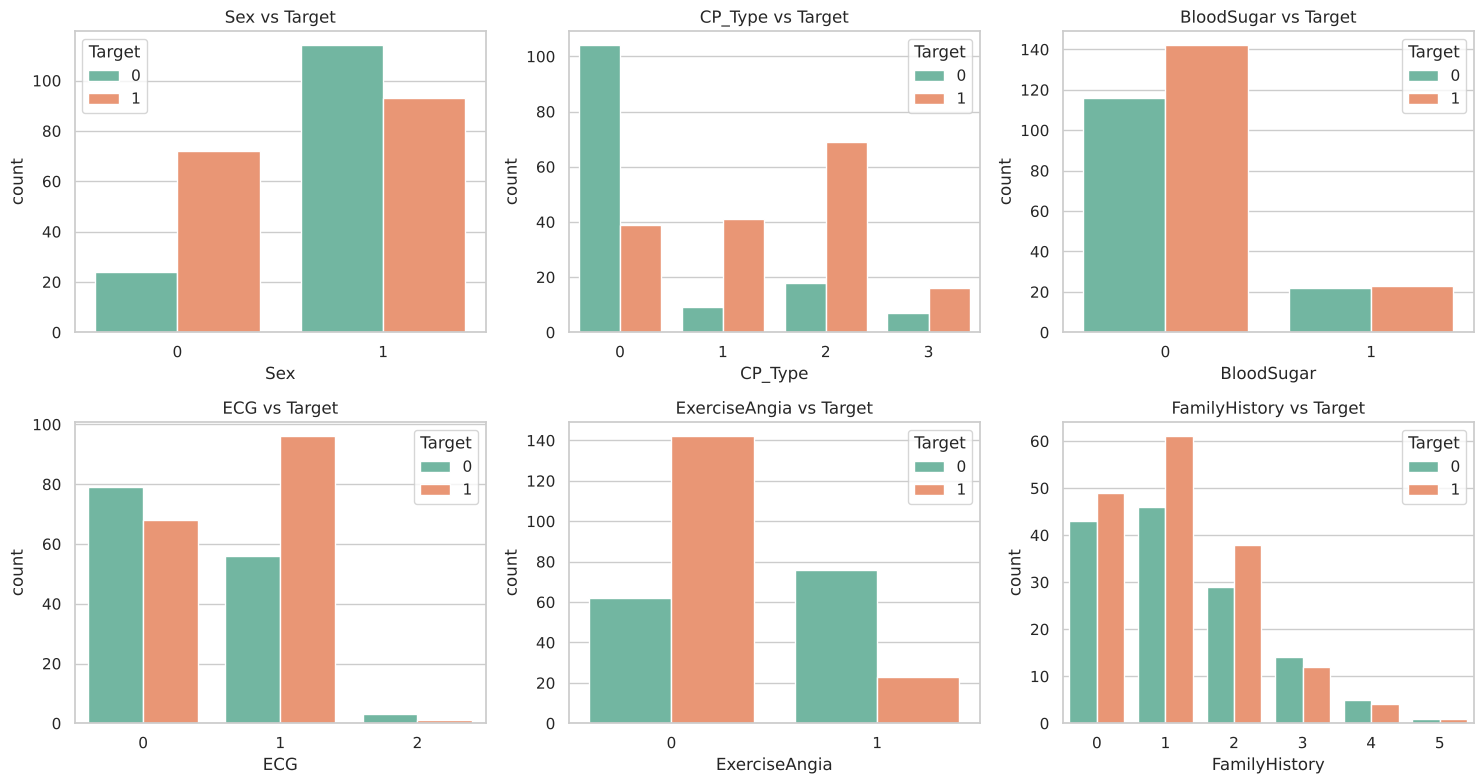

In [10]:
# Categorical / discrete features vs Target
cat_cols = ["Sex", "CP_Type", "BloodSugar", "ECG", "ExerciseAngia", "FamilyHistory"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=col, hue="Target", data=df, ax=ax, palette="Set2")
    ax.set_title(f"{col} vs Target")
plt.tight_layout(); plt.show()

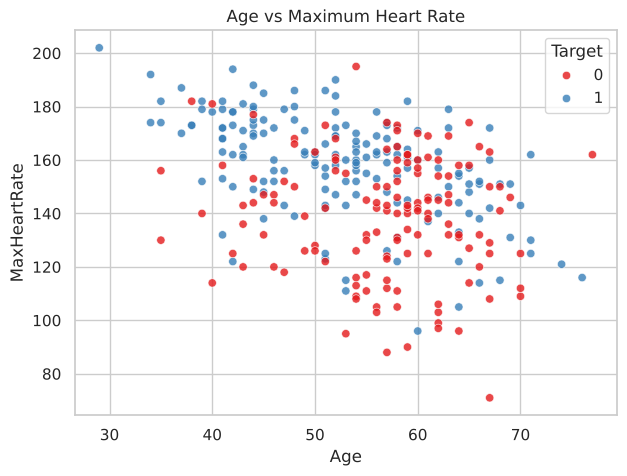

In [11]:
# Age vs MaxHeartRate coloured by Target
plt.figure(figsize=(7, 5))
sns.scatterplot(x="Age", y="MaxHeartRate", hue="Target", data=df, palette="Set1", alpha=0.8)
plt.title("Age vs Maximum Heart Rate")
plt.show()

**Insights from the plots**
- The classes are fairly balanced (about 54% "more chance" vs 46% "less chance"), so plain accuracy is a reasonable metric, though we will also look at recall and ROC-AUC.
- Patients with **higher chance** tend to have a **higher maximum heart rate**, are **younger**, and mostly have chest-pain types 1-3 (i.e., not typical angina).
- **Exercise-induced angina = 1** is more common in the *less chance* group.
- Cholesterol and blood pressure show a few extreme values (outliers) and right-skew, which we will handle in pre-processing.

### 2.4 Correlation analysis

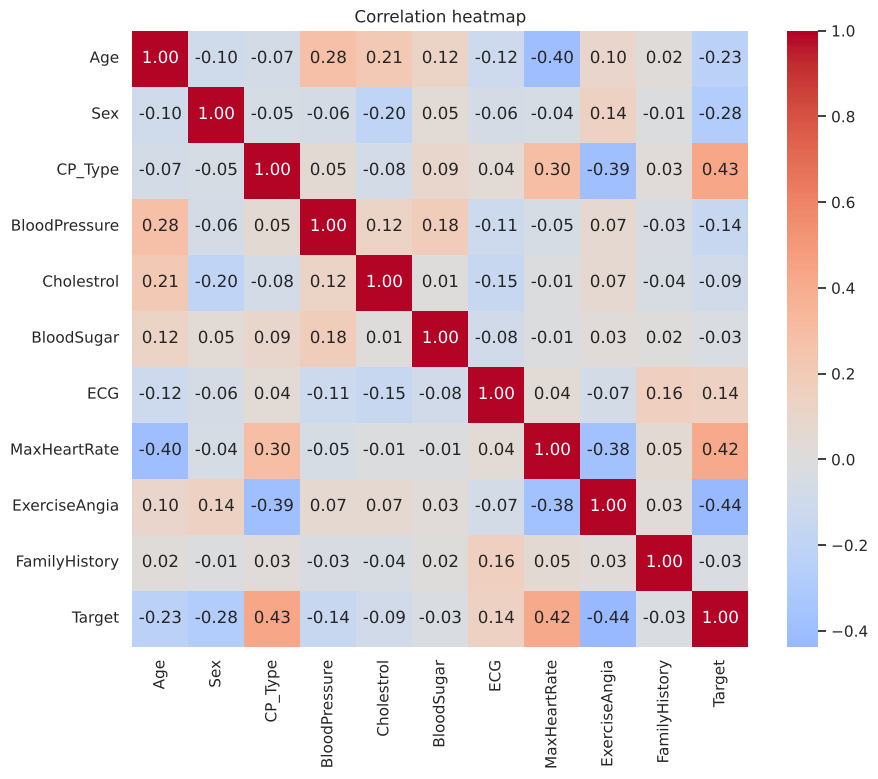

Correlation of each feature with Target:
ExerciseAngia   -0.437
CP_Type          0.434
MaxHeartRate     0.422
Sex             -0.281
Age             -0.225
BloodPressure   -0.145
ECG              0.137
Cholestrol      -0.085
FamilyHistory   -0.029
BloodSugar      -0.028
Name: Target, dtype: float64


In [12]:
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.show()

print("Correlation of each feature with Target:")
print(corr["Target"].drop("Target").sort_values(key=abs, ascending=False).round(3))

In [13]:
# Check for strongly inter-correlated features (multicollinearity)
feat_corr = corr.drop("Target").drop("Target", axis=1)
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
         .stack().rename("corr").reset_index())
pairs["abs"] = pairs["corr"].abs()
print(pairs.sort_values("abs", ascending=False).head(5).drop(columns="abs"))

         level_0        level_1      corr
7            Age   MaxHeartRate -0.398522
28       CP_Type  ExerciseAngia -0.394280
78  MaxHeartRate  ExerciseAngia -0.378812
27       CP_Type   MaxHeartRate  0.295762
3            Age  BloodPressure  0.279351


**Will the correlation analysis affect feature selection? Yes – justification:**

1. **Feature-target correlation tells us which features carry signal.** `CP_Type`, `MaxHeartRate` and `ExerciseAngia` have the strongest correlation with `Target` (about 0.42-0.44 in absolute value), followed by `Sex` and `Age`. On the other hand, `BloodSugar`, `FamilyHistory` and `Cholestrol` have almost zero linear correlation (|r| < 0.1), so they are candidates to be dropped or at least checked again with other importance methods.
2. **Feature-feature correlation tells us about redundancy.** The highest correlation between two input features is only moderate (the top pair is printed above, around 0.4), so there is **no severe multicollinearity**. This means we do not have to drop a feature just because it duplicates another one. This is important for Logistic Regression, whose coefficients become unstable when features are highly correlated.
3. **Limitation:** Pearson correlation only measures *linear* relationships. A feature with low correlation may still help a Decision Tree through non-linear splits. So the correlation result is used as one input to feature selection, and we confirm it with Mutual Information and Random Forest importance in the next step.

## 3. Data Pre-processing and Cleaning

### 3.1 Missing values and duplicates

In [14]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Age              0
Sex              0
CP_Type          0
BloodPressure    0
Cholestrol       0
BloodSugar       0
ECG              0
MaxHeartRate     0
ExerciseAngia    0
FamilyHistory    0
Target           0
dtype: int64

Total missing values: 0
Duplicate rows: 0


**Result:** No missing values and no duplicate rows, so no imputation or row removal is needed.

### 3.2 Outlier detection (IQR method)

In [15]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in num_cols:
    lo, hi = iqr_bounds(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append([col, round(lo, 1), round(hi, 1), n_out, round(df[col].skew(), 2)])
display(pd.DataFrame(rows, columns=["Feature", "Lower bound", "Upper bound", "# Outliers", "Skewness"]))

,Feature,Lower bound,Upper bound,# Outliers,Skewness
0,Age,27.2,81.2,0,-0.20
1,BloodPressure,90.0,170.0,9,0.71
2,Cholestrol,115.8,369.8,5,1.14
3,MaxHeartRate,84.8,214.8,1,-0.54


**Decision:** The dataset is small (303 rows), so deleting outlier rows would throw away valuable patients. Instead we use **capping (winsorizing) at the IQR bounds**, which keeps every row but limits the pull of extreme values (for example, a cholesterol of 564). Cholesterol is also right-skewed (skew > 1), so we compare a log transform too.

In [16]:
df_clean = df.copy()
for col in num_cols:
    lo, hi = iqr_bounds(df_clean[col])
    df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)

# Skewness before / after capping
print(pd.DataFrame({"before": df[num_cols].skew(), "after_capping": df_clean[num_cols].skew()}).round(2))

# Also test a log transform on Cholestrol (the most skewed feature)
print("\nCholestrol skew after capping + log1p:", round(np.log1p(df_clean["Cholestrol"]).skew(), 2))

               before  after_capping
Age             -0.20          -0.20
BloodPressure    0.71           0.39
Cholestrol       1.14           0.33
MaxHeartRate    -0.54          -0.49

Cholestrol skew after capping + log1p: -0.21


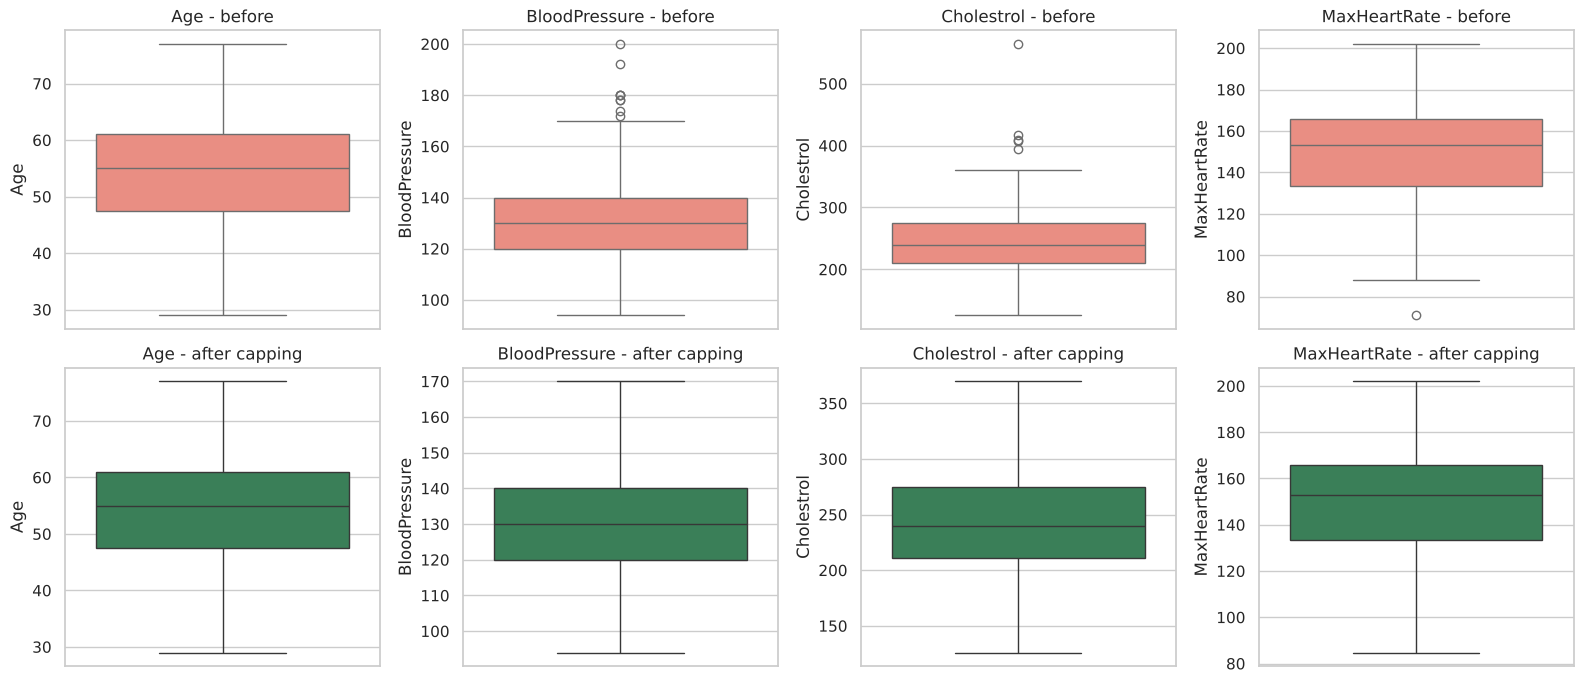

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[0, i], color="salmon");       axes[0, i].set_title(f"{col} - before")
    sns.boxplot(y=df_clean[col], ax=axes[1, i], color="seagreen"); axes[1, i].set_title(f"{col} - after capping")
plt.tight_layout(); plt.show()

**Skewness decision:** After capping, the skew of all numeric features falls well inside the acceptable range (all four are below 0.5 in absolute value), so we **do not apply a log transform**. The capping already fixed the skew caused by the extreme values, and a log transform would make coefficients harder to interpret without any real gain.

### 3.3 Feature engineering

**Encoding:** `CP_Type` and `ECG` are *nominal* codes (0, 1, 2, 3 are categories, not a quantity - 3 is not "three times" 1). Feeding them as numbers to Logistic Regression would wrongly imply an order, so we **one-hot encode** them (`drop_first=True` avoids the dummy-variable trap). `Sex`, `BloodSugar` and `ExerciseAngia` are already binary 0/1, and `FamilyHistory` is a count, so they stay as they are.

In [18]:
df_fe = pd.get_dummies(df_clean, columns=["CP_Type", "ECG"], drop_first=True, dtype=int)
print("Shape after encoding:", df_fe.shape)
display(df_fe.head())

Shape after encoding: (303, 14)


,Age,Sex,BloodPressure,Cholestrol,BloodSugar,MaxHeartRate,ExerciseAngia,FamilyHistory,Target,CP_Type_1,CP_Type_2,CP_Type_3,ECG_1,ECG_2
0,63,1,145,233.0,1,150.0,0,2,1,0,0,1,0,0
1,37,1,130,250.0,0,187.0,0,1,1,0,1,0,1,0
2,41,0,130,204.0,0,172.0,0,0,1,1,0,0,0,0
3,56,1,120,236.0,0,178.0,0,1,1,1,0,0,1,0
4,57,0,120,354.0,0,163.0,1,0,1,0,0,0,1,0


### 3.4 Feature importance (three different techniques)

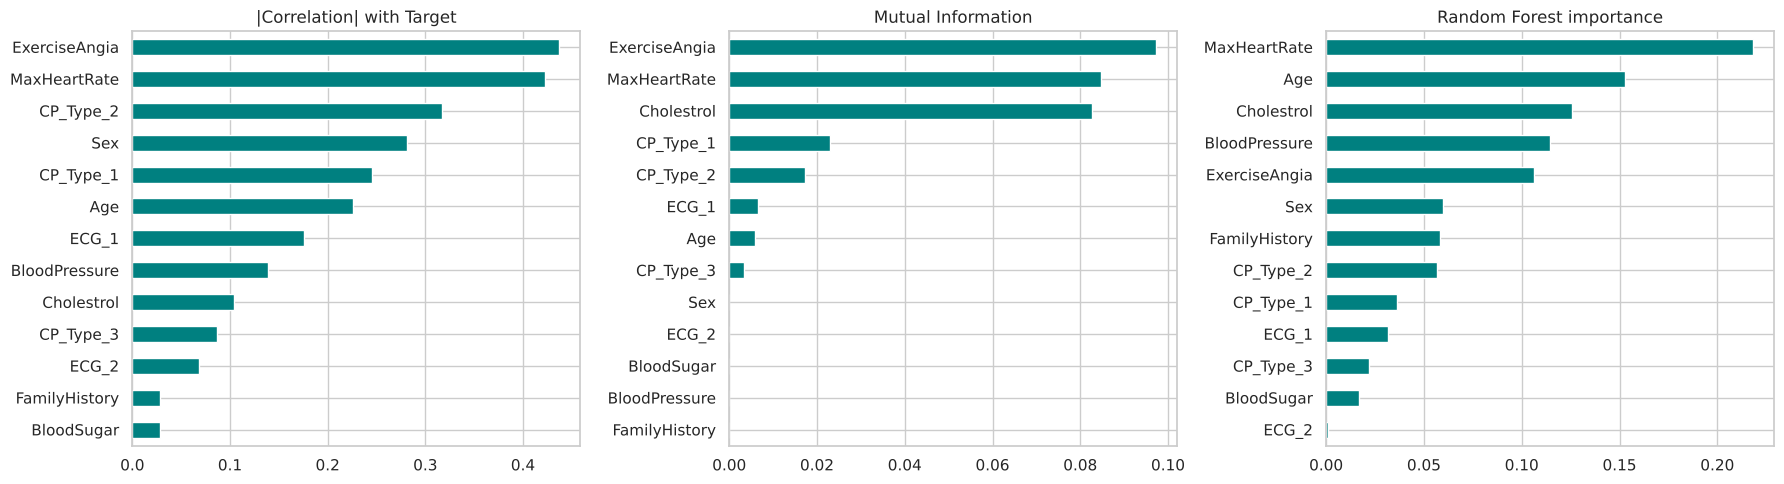

,corr_rank,MI_rank,RF_rank,avg_rank
MaxHeartRate,2.0,2.0,1.0,1.666667
ExerciseAngia,1.0,1.0,5.0,2.333333
Age,6.0,7.0,2.0,5.000000
Cholestrol,9.0,3.0,3.0,5.000000
CP_Type_2,3.0,5.0,8.0,5.333333
CP_Type_1,5.0,4.0,9.0,6.000000
Sex,4.0,11.0,6.0,7.000000
ECG_1,7.0,6.0,10.0,7.666667
BloodPressure,8.0,11.0,4.0,7.666667
CP_Type_3,10.0,8.0,11.0,9.666667


In [19]:
X_all = df_fe.drop("Target", axis=1)
y_all = df_fe["Target"]

# 1) Absolute correlation with target
corr_imp = X_all.corrwith(y_all).abs().sort_values(ascending=False)

# 2) Mutual information (captures non-linear dependence too)
mi = pd.Series(mutual_info_classif(X_all, y_all, random_state=RANDOM_STATE), index=X_all.columns).sort_values(ascending=False)

# 3) Random Forest feature importance
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_all, y_all)
rf_imp = pd.Series(rf.feature_importances_, index=X_all.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s, t in zip(axes, [corr_imp, mi, rf_imp], ["|Correlation| with Target", "Mutual Information", "Random Forest importance"]):
    s.sort_values().plot.barh(ax=ax, color="teal"); ax.set_title(t)
plt.tight_layout(); plt.show()

imp_table = pd.DataFrame({"corr_rank": corr_imp.rank(ascending=False), "MI_rank": mi.rank(ascending=False),
                          "RF_rank": rf_imp.rank(ascending=False)})
imp_table["avg_rank"] = imp_table.mean(axis=1)
display(imp_table.sort_values("avg_rank"))

**Feature selection decision:** The three methods agree on the top group (`MaxHeartRate`, `ExerciseAngia`, chest-pain dummies, `Age`, `Sex`...). The features with the worst average rank (`BloodSugar`, `FamilyHistory`, `ECG_2`, `CP_Type_3`) contribute very little. However, with only ~300 rows and ~12 features the risk of overfitting from keeping weak features is small, and a weak feature can be useful in combination with others. So we **keep all features** for the main models and later test a reduced feature set (top features only) to confirm whether dropping the weak ones really changes anything.

### 3.5 Feature transformation: Standardization

**Why Standardization (z-score) and not Min-Max?**
- Logistic Regression is trained with gradient-based optimization and uses L2 regularization; both are sensitive to feature scale. `Cholestrol` (~250) would dominate `Sex` (0/1) if left unscaled. Standardization puts every continuous feature on mean 0 / std 1.
- Standardization is less affected by remaining outliers than Min-Max (which squeezes everything between the min and max).
- Decision Trees are scale-invariant, so scaling does not change their result, but it does no harm and lets both models share the same pipeline.

Only the continuous columns are scaled; binary / one-hot columns are left untouched.

**Avoiding data leakage:** the scaler is placed inside a scikit-learn `Pipeline`, so it is **fitted only on the training fold** and then applied to validation/test data. Fitting it on the full data before splitting would leak test-set information into training.

In [20]:
scale_cols = ["Age", "BloodPressure", "Cholestrol", "MaxHeartRate", "FamilyHistory"]

# Quick visual of the effect of scaling (for illustration only; real scaling happens inside the pipeline)
demo = pd.DataFrame(StandardScaler().fit_transform(df_fe[scale_cols]), columns=scale_cols)
print("Before scaling:"); display(df_fe[scale_cols].describe().loc[["mean", "std"]].round(2))
print("After scaling (illustration):"); display(demo.describe().loc[["mean", "std"]].round(2))

Before scaling:


,Age,BloodPressure,Cholestrol,MaxHeartRate,FamilyHistory
mean,54.37,131.28,245.13,149.69,1.2
std,9.08,16.58,47.55,22.76,1.1


After scaling (illustration):


,Age,BloodPressure,Cholestrol,MaxHeartRate,FamilyHistory
mean,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 4. Model Building

### 4.1 Train-test split (80% train / 20% test)

In [21]:
X = df_fe.drop("Target", axis=1)
y = df_fe["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train target share:\n", y_train.value_counts(normalize=True).round(3))
print("Test target share:\n",  y_test.value_counts(normalize=True).round(3))

Train: (242, 13)  Test: (61, 13)
Train target share:
 Target
1    0.545
0    0.455
Name: proportion, dtype: float64
Test target share:
 Target
1    0.541
0    0.459
Name: proportion, dtype: float64


**Justification of the 80/20 split:**
- With only 303 patients, we need most of the data for training (80% = 242 rows) so the models can learn properly, but we still need a test set large enough (61 rows) to give a meaningful estimate of performance.
- We use **`stratify=y`** so both train and test keep the same class ratio (~54/46). Otherwise a random split on a small dataset can give a test set with very different class balance.
- `random_state=42` makes the result reproducible.

### 4.2 Pipelines

In [22]:
preprocess = ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough")

lr_pipe = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
dt_pipe = Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Baseline (untuned) models, cross-validated on the training set
for name, p in [("Logistic Regression", lr_pipe), ("Decision Tree", dt_pipe)]:
    s = cross_val_score(p, X_train, y_train, cv=cv, scoring="accuracy")
    print(f"{name:20s} baseline CV accuracy: {s.mean():.3f} (+/- {s.std():.3f})")

Logistic Regression  baseline CV accuracy: 0.760 (+/- 0.114)
Decision Tree        baseline CV accuracy: 0.616 (+/- 0.065)


### 4.3 Hyperparameter tuning with 5-fold cross-validation

We use `GridSearchCV` with **stratified 5-fold cross-validation on the training data only**, so the test set stays untouched until the final evaluation.

- **Logistic Regression:** `C` (inverse regularization strength - small C = stronger regularization, helps against overfitting), `penalty` (L1 / L2) and `solver`.
- **Decision Tree:** `max_depth`, `min_samples_split`, `min_samples_leaf` and `criterion`. An unrestricted tree memorizes the training data, so limiting depth / leaf size is the main way to control overfitting. (The "number of trees" hint in the assignment applies to ensembles such as Random Forest; a single Decision Tree has no such parameter.)
- **Scoring:** `roc_auc` is used to pick the best model because it does not depend on a threshold and works well on a slightly imbalanced target.

In [23]:
lr_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"],
}
dt_grid = {
    "clf__max_depth": [2, 3, 4, 5, 6, 8, None],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__criterion": ["gini", "entropy"],
}

lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
dt_search = GridSearchCV(dt_pipe, dt_grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("Logistic Regression best params:", lr_search.best_params_)
print("Logistic Regression best CV ROC-AUC: %.3f" % lr_search.best_score_)
print()
print("Decision Tree best params:", dt_search.best_params_)
print("Decision Tree best CV ROC-AUC: %.3f" % dt_search.best_score_)

Logistic Regression best params: {'clf__C': 100, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
Logistic Regression best CV ROC-AUC: 0.846

Decision Tree best params: {'clf__criterion': 'gini', 'clf__max_depth': 2, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2}
Decision Tree best CV ROC-AUC: 0.738


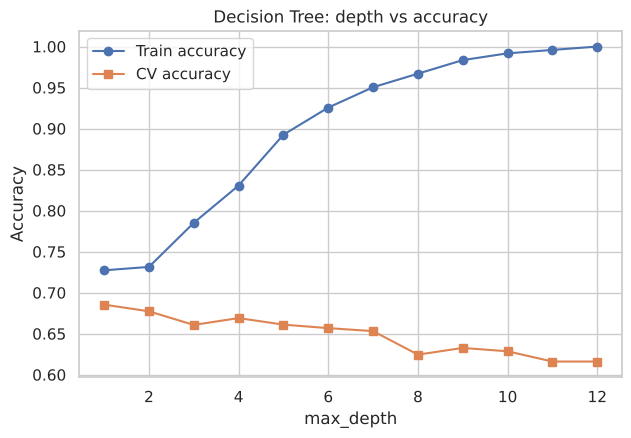

In [24]:
# Effect of max_depth on the Decision Tree (training vs cross-validation score) -> shows over/under-fitting
depths = list(range(1, 13))
tr_sc, cv_sc = [], []
for d in depths:
    m = Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    m.fit(X_train, y_train)
    tr_sc.append(m.score(X_train, y_train))
    cv_sc.append(cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy").mean())

plt.figure(figsize=(7, 4.5))
plt.plot(depths, tr_sc, "o-", label="Train accuracy")
plt.plot(depths, cv_sc, "s-", label="CV accuracy")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Decision Tree: depth vs accuracy"); plt.legend()
plt.show()

{0.001: np.float64(0.731), 0.01: np.float64(0.731), 0.1: np.float64(0.772), 1: np.float64(0.756), 10: np.float64(0.752), 100: np.float64(0.752)}


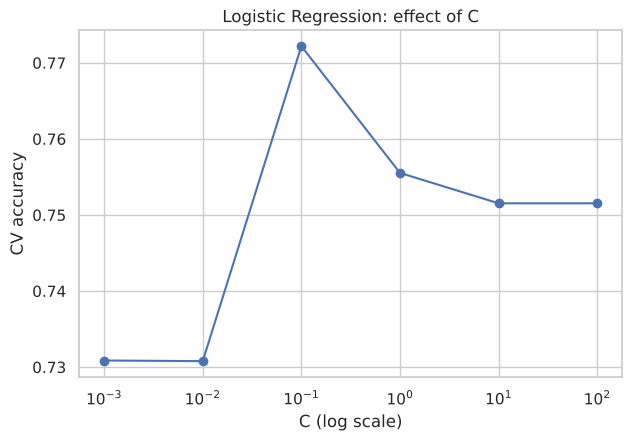

In [25]:
# Same for Logistic Regression: effect of regularization strength C
Cs = [0.001, 0.01, 0.1, 1, 10, 100]
cs_scores = []
for c in Cs:
    m = Pipeline([("prep", preprocess), ("clf", LogisticRegression(C=c, penalty="l2", solver="liblinear"))])
    cs_scores.append(cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy").mean())
print(dict(zip(Cs, np.round(cs_scores, 3))))

plt.figure(figsize=(7, 4.5))
plt.semilogx(Cs, cs_scores, "o-")
plt.xlabel("C (log scale)"); plt.ylabel("CV accuracy"); plt.title("Logistic Regression: effect of C")
plt.show()

**Tuning justification:**
- **Decision Tree:** Training accuracy climbs from about 73% (depth 1) to 100% (depth 12), while cross-validation accuracy stays flat at roughly 65-68% and is best at very shallow depths. Deep trees are just memorizing the training patients (over-fitting), so cross-validated grid search selects a very shallow tree (`max_depth = 2`). The untuned, fully grown tree had a baseline CV accuracy of only about 0.62, so tuning clearly helped.
- **Logistic Regression:** Very strong regularization (`C` = 0.001 or 0.01) under-fits (CV accuracy about 0.73), and accuracy peaks around `C` = 0.1 (about 0.77), then stays roughly flat (0.75) for larger `C`. Since the differences for `C` >= 0.1 are well within the fold-to-fold noise (std about 0.1), the grid search, which uses ROC-AUC, picks `C = 100` with an L1 penalty. In practice this means that with 12 features and 242 training rows, regularization is not critical for Logistic Regression.
- Cross-validation (instead of a single validation split) gives a more reliable estimate on such a small dataset, and the test set was never used during tuning.

### 4.4 Trying different train/test split ratios

,Train/Test,Model,Accuracy,F1,ROC-AUC
0,90/10,Logistic Regression,0.774,0.811,0.752
1,90/10,Decision Tree,0.645,0.744,0.637
2,80/20,Logistic Regression,0.754,0.783,0.835
3,80/20,Decision Tree,0.705,0.780,0.795
4,70/30,Logistic Regression,0.736,0.765,0.841
5,70/30,Decision Tree,0.670,0.700,0.690
6,60/40,Logistic Regression,0.770,0.797,0.846
7,60/40,Decision Tree,0.705,0.763,0.698


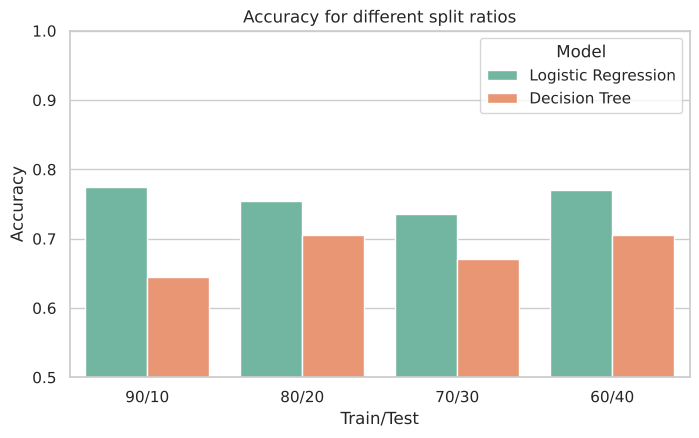

In [26]:
def run_split(test_size):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y)
    out = {}
    for name, search in [("Logistic Regression", lr_search), ("Decision Tree", dt_search)]:
        model = clone(search.best_estimator_)      # fresh, unfitted copy with the same tuned hyper-parameters
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        out[name] = (accuracy_score(yte, pred), f1_score(yte, pred), roc_auc_score(yte, model.predict_proba(Xte)[:, 1]))
    return out

rows = []
for ratio in [0.10, 0.20, 0.30, 0.40]:
    res = run_split(ratio)
    for name, (acc, f1, auc) in res.items():
        rows.append([f"{int((1-ratio)*100)}/{int(ratio*100)}", name, round(acc, 3), round(f1, 3), round(auc, 3)])
split_df = pd.DataFrame(rows, columns=["Train/Test", "Model", "Accuracy", "F1", "ROC-AUC"])
display(split_df)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=split_df, x="Train/Test", y="Accuracy", hue="Model", palette="Set2")
plt.ylim(0.5, 1); plt.title("Accuracy for different split ratios"); plt.show()

**Observation:** Logistic Regression beats the Decision Tree at every ratio (accuracy 0.74-0.77 vs 0.65-0.71; ROC-AUC 0.75-0.85 vs 0.64-0.80). The Decision Tree's ROC-AUC swings much more between ratios (0.64 to 0.80) than Logistic Regression's, showing higher variance. All numbers are noisy because the test sets are small (the 90/10 split has only ~31 patients, so a single wrong prediction moves accuracy by about 3%). The 80/20 split is the required one and gives a good balance between training data and test reliability, so it is used for the final evaluation.

## 5. Performance Evaluation

In [27]:
best_lr = lr_search.best_estimator_
best_dt = dt_search.best_estimator_

results, preds, probs = {}, {}, {}
for name, model in [("Logistic Regression", best_lr), ("Decision Tree", best_dt)]:
    p = model.predict(X_test); pr = model.predict_proba(X_test)[:, 1]
    preds[name], probs[name] = p, pr
    results[name] = {
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall":    recall_score(y_test, p),
        "F1-score":  f1_score(y_test, p),
        "ROC-AUC":   roc_auc_score(y_test, pr),
        "CV ROC-AUC (train)": (lr_search if name == "Logistic Regression" else dt_search).best_score_,
    }
res_df = pd.DataFrame(results).T.round(3)
display(res_df)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV ROC-AUC (train)
Logistic Regression,0.754,0.750,0.818,0.783,0.835,0.846
Decision Tree,0.705,0.653,0.970,0.780,0.795,0.738


In [28]:
for name in preds:
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, preds[name], target_names=["Less chance (0)", "More chance (1)"]))

Logistic Regression
                 precision    recall  f1-score   support

Less chance (0)       0.76      0.68      0.72        28
More chance (1)       0.75      0.82      0.78        33

       accuracy                           0.75        61
      macro avg       0.76      0.75      0.75        61
   weighted avg       0.75      0.75      0.75        61

Decision Tree
                 precision    recall  f1-score   support

Less chance (0)       0.92      0.39      0.55        28
More chance (1)       0.65      0.97      0.78        33

       accuracy                           0.70        61
      macro avg       0.78      0.68      0.67        61
   weighted avg       0.77      0.70      0.67        61



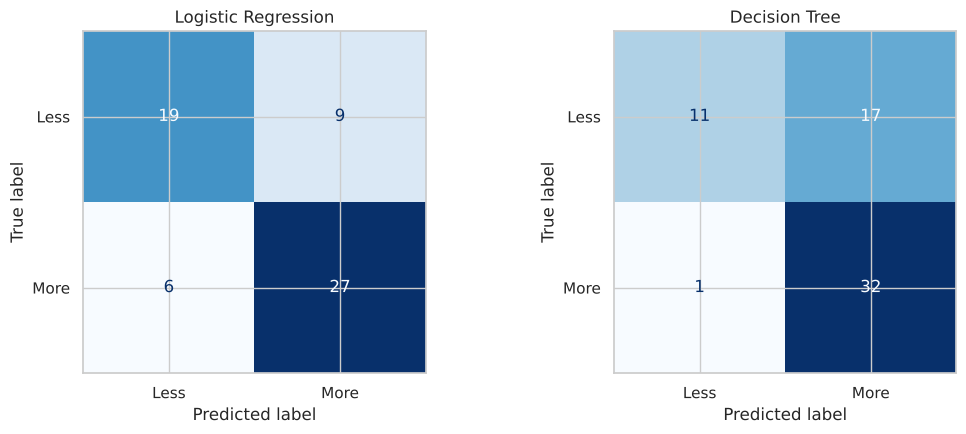

In [29]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, preds):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]), display_labels=["Less", "More"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

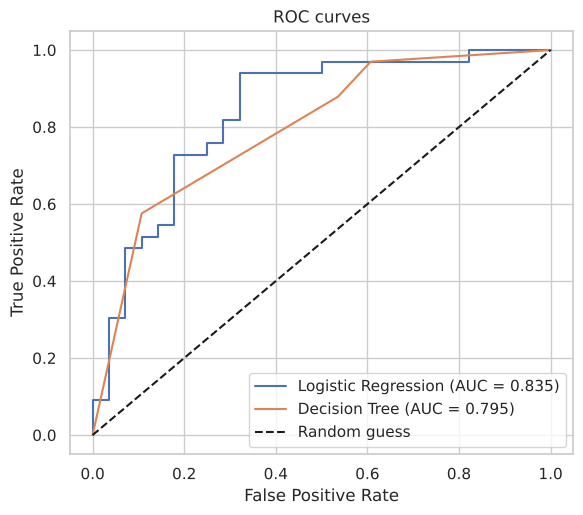

In [30]:
# ROC curves
plt.figure(figsize=(6.5, 5.5))
for name in probs:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves"); plt.legend()
plt.show()

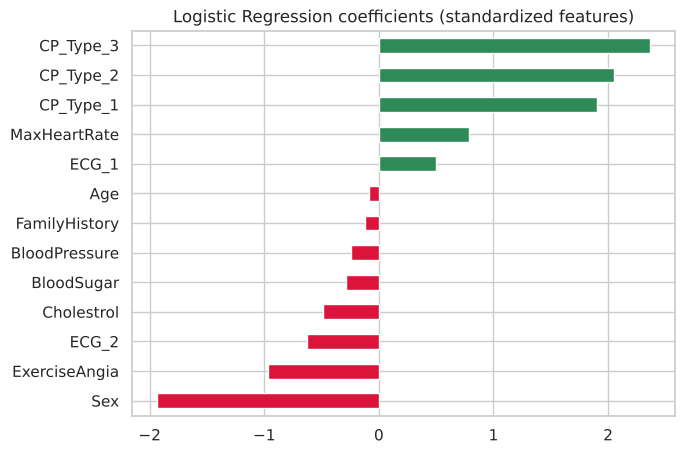

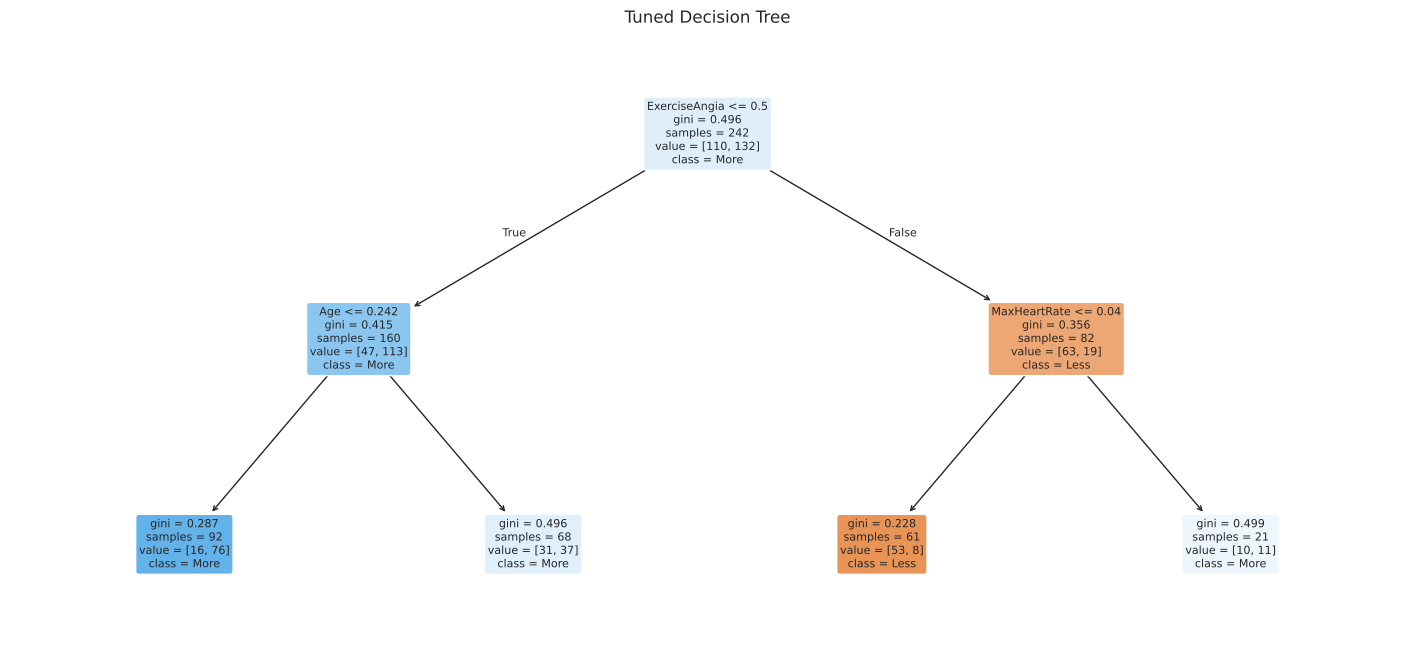

In [31]:
# Model interpretation: LR coefficients and the Decision Tree structure
coef_names = scale_cols + [c for c in X.columns if c not in scale_cols]
coefs = pd.Series(best_lr.named_steps["clf"].coef_[0], index=coef_names).sort_values()
plt.figure(figsize=(7, 5)); coefs.plot.barh(color=np.where(coefs > 0, "seagreen", "crimson"))
plt.title("Logistic Regression coefficients (standardized features)"); plt.show()

plt.figure(figsize=(18, 8))
plot_tree(best_dt.named_steps["clf"], feature_names=coef_names, class_names=["Less", "More"], filled=True, rounded=True, fontsize=8)
plt.title("Tuned Decision Tree"); plt.show()

In [32]:
# Does dropping the weak features change anything? (reduced feature set check)
top_feats = [c for c in imp_table.sort_values("avg_rank").index[:8]]
print("Reduced feature set:", top_feats)
sc = [c for c in scale_cols if c in top_feats]
prep_r = ColumnTransformer([("scale", StandardScaler(), sc)], remainder="passthrough")
for name, clf in [("Logistic Regression", LogisticRegression(C=lr_search.best_params_["clf__C"], penalty=lr_search.best_params_["clf__penalty"], solver="liblinear")),
                  ("Decision Tree", DecisionTreeClassifier(max_depth=dt_search.best_params_["clf__max_depth"],
                                                           min_samples_split=dt_search.best_params_["clf__min_samples_split"],
                                                           min_samples_leaf=dt_search.best_params_["clf__min_samples_leaf"],
                                                           criterion=dt_search.best_params_["clf__criterion"], random_state=RANDOM_STATE))]:
    full = cross_val_score(Pipeline([("p", preprocess), ("c", clf)]), X_train, y_train, cv=cv, scoring="roc_auc").mean()
    red  = cross_val_score(Pipeline([("p", prep_r), ("c", clf)]), X_train[top_feats], y_train, cv=cv, scoring="roc_auc").mean()
    print(f"{name:20s} CV ROC-AUC  all features: {full:.3f} | top-8 features: {red:.3f}")

Reduced feature set: ['MaxHeartRate', 'ExerciseAngia', 'Age', 'Cholestrol', 'CP_Type_2', 'CP_Type_1', 'Sex', 'ECG_1']


Logistic Regression  CV ROC-AUC  all features: 0.846 | top-8 features: 0.844
Decision Tree        CV ROC-AUC  all features: 0.738 | top-8 features: 0.738


### Conclusion: which model is better and why?

**Test-set results (80/20 split, 61 patients)**

| Metric | Logistic Regression | Decision Tree |
|---|---|---|
| Accuracy | 0.754 | 0.705 |
| Precision | 0.750 | 0.653 |
| Recall | 0.818 | 0.970 |
| F1-score | 0.783 | 0.780 |
| ROC-AUC | 0.835 | 0.795 |
| CV ROC-AUC (train) | 0.846 | 0.738 |

**Winner: Logistic Regression**, and the reasons are:

1. **Better overall discrimination.** Its ROC-AUC (0.835 test, 0.846 in cross-validation) is higher than the tree's (0.795 test, 0.738 in cross-validation), and it is higher at every split ratio we tried. ROC-AUC is threshold independent, so it is the fairest single comparison.
2. **Better balanced errors.** The Decision Tree reaches a recall of 0.97 for "more chance", but only because it predicts "more chance" for most patients: its recall for the "less chance" class is just 0.39 (17 of 28 "less chance" patients are wrongly flagged), which drops its precision to 0.65. Logistic Regression is more balanced (recall 0.82 for class 1 and 0.68 for class 0, precision 0.75). F1 is almost identical (0.78 vs 0.78), so the tree's high recall does not make it a better model.
3. **Why it fits this data.** The signals in this dataset (max heart rate, exercise-induced angina, chest-pain type, age, sex) act mostly in an additive, roughly linear way on the risk, which is exactly what Logistic Regression models. A depth-2 tree can use only 2 levels of splits (at most 4 leaves), so it is too coarse, while a deeper tree over-fits the 242 training rows (train accuracy goes to 100% but CV accuracy stays near 65%). Logistic Regression has few parameters, so it has lower variance on small data.
4. **Stability.** Across 90/10 to 60/40 splits the Decision Tree's performance swings far more than Logistic Regression's.

**When might the Decision Tree still be preferred?** If the goal is a simple, human-readable rule set for doctors and **missing a patient is much worse than a false alarm**, the tree's very high recall (0.97) is attractive. Even then, the same effect can be achieved with Logistic Regression by lowering its decision threshold.

**Other observations**
- Dropping the 5 weakest features (`BloodSugar`, `FamilyHistory`, `ECG_2`, `CP_Type_3`, `BloodPressure`) changed the cross-validated ROC-AUC by only about 0.002 for Logistic Regression and none for the tree, confirming that these features add almost nothing.
- **Limitations:** The dataset has only 303 patients, so the test set (61) is small and metrics have a wide margin of error (a single patient is about 1.6 percentage points). Results should be seen as indicative, not final. More data, or ensemble methods such as Random Forest or Gradient Boosting, could improve performance, and a medical use would need external validation.